In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

## Question 1

#### (a) Constructing the graph and writing python code that create the graph

In [4]:
G = nx.Graph()

In [5]:
nodes = [1,2,3,4,5,6,7,8,9]

In [6]:
edges = [(4,7),(1,4),(1,2),(4,5),(5,2),(5,8),(8,9),(9,6),(6,3), (3,2),(6,5)]

In [7]:
G.add_nodes_from(nodes)

In [8]:
G.add_edges_from(edges)

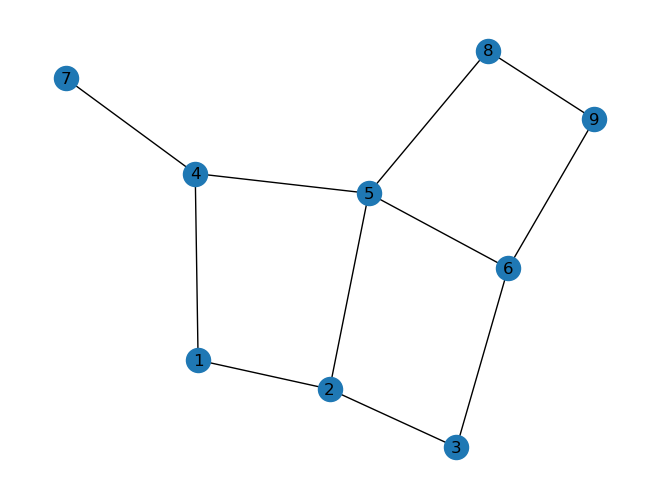

In [9]:
nx.draw(G, with_labels = True)

### (b) Computing the adjacency matrix A of the graph

In [11]:
#adjacency_matrix = nx.adjacency_matrix(G)
A = nx.to_numpy_array(G)

### Commenting on the graph's symmetry.

##### The adjacency matrix is symmetric

### Solving (C. i, ii, iii) by hand





$$ \begin{array}{|c|c|c|}
\hline
\text{Node} & \text{Degree} \\
\hline
1  & 2 \\
2 & 3 \\
3  & 2 \\
4 & 3 \\
5 & 4 \\
6  & 3 \\
7  & 1 \\
8 & 2 \\
9 & 2 \\
\hline
\end{array}
$$




Degree Sequence
$$
(1,2, 2, 2, 2, 3, 3, 3, 4)
$$

Degree Distribution

$$
\begin{array}{|c|c|c|}
\hline
\text{Degree (k)} & \text{Count of nodes} & P(k) \\
\hline
1 & 1 & \frac{1}{9}\\
2 & 4 & \frac{4}{9}\\
3 & 3 & \frac{3}{9}\\
4 & 1 & \frac{1}{9}\\
\hline
\end{array}
$$

<img src="Q1.jpg" width="600" height="200" alt="Description">

The *maximum degree* is \(4\) and it is achieved by *node 5*.  

The *minimum degree* is \(1\) and it is achieved by *node 7*.

## Soving with NetworkX

### (C i) Degree Sequence

In [20]:
L = []
for i in nodes:
    L.append(G.degree(i))
print(sorted(L))

[1, 2, 2, 2, 2, 3, 3, 3, 4]


### (C ii) Degree Distribution

In [22]:
from collections import Counter

def degree_distribution(A):            
    dist = Counter(L)            
    degrees = sorted(dist.keys())
    return degrees, dict(dist)


degrees, distribution = degree_distribution(A)
print("Degree distribution:", distribution)

Degree distribution: {2: 4, 3: 3, 4: 1, 1: 1}


### Degree Distribution Table

| k | P(k) |
|---|------|
| 1 | 1    |
| 2 | 4    |
| 3 | 2    |
| 4 | 1    |


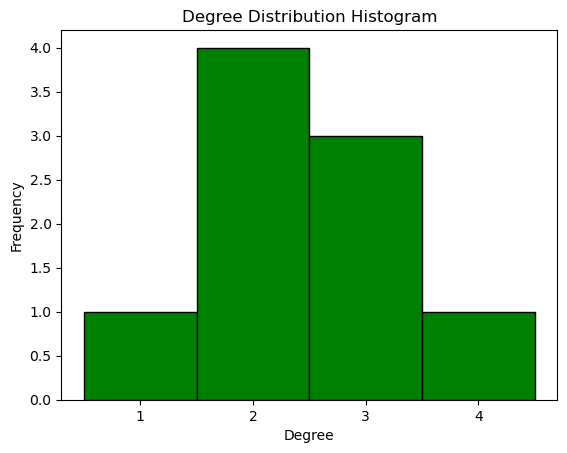

In [24]:
plt.figure()
plt.xticks([1,2,3,4],["1","2","3","4"] )
plt.hist(L, bins = [1,2,3,4,5], density= False, color = "g", align = 'left', edgecolor = 'black');
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution Histogram")
plt.show()

In [25]:
maximum_degree = max(L)
maximum_degree

4

In [26]:
minimum_degree = min(L)
minimum_degree

1

### (d) Extracting and displaying the edge list of the graph

In [28]:
print(list(G.edges()))

[(1, 4), (1, 2), (2, 5), (2, 3), (3, 6), (4, 7), (4, 5), (5, 8), (5, 6), (6, 9), (8, 9)]


#### Explaination


The adjacency matrix of a graph with 9 nodes stores 81 bytes.

An edge list stores 8 bytes per edge.

Bytes saved = 81−8p, where p is the number of edges.

A graph is sparse when $m ≪ n^{2}$, and in this case, the edge list saves many bytes.


### (e) Computing the average clustering coefficient

In [32]:
Average_Clustering_Coefficient = nx.average_clustering(G)
Average_Clustering_Coefficient 

0.0

### Interpretation of average alustering coefficient 

The average clustering coefficient tells us how likely a node’s neighbors are also connected to each other.

Since the result is 0, it means that the neighbors of a node are rarely connected to each other.

### (f) Computing a closed walk of length 4

### Manually

$$
A = 
\begin{bmatrix}
0 & 1 & 0 & 1 & 0 & 0 & 0 & 0 & 0 \\
1 & 0 & 1 & 0 & 1 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 & 0 & 1 & 0 & 0 & 0 \\
1 & 0 & 0 & 0 & 1 & 0 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 & 1 & 0 \\
0 & 0 & 1 & 0 & 1 & 0 & 0 & 0 & 1 \\
0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 & 1 \\
0 & 0 & 0 & 0 & 0 & 1 & 0 & 1 & 0
\end{bmatrix}
$$

$$
A^2 = 
\begin{bmatrix}
2 & 0 & 1 & 0 & 2 & 0 & 1 & 0 & 0 \\
0 & 3 & 0 & 2 & 0 & 2 & 0 & 1 & 0 \\
1 & 0 & 2 & 0 & 2 & 0 & 0 & 0 & 1 \\
0 & 2 & 0 & 3 & 0 & 1 & 0 & 1 & 0 \\
2 & 0 & 2 & 0 & 4 & 0 & 1 & 0 & 2 \\
0 & 2 & 0 & 1 & 0 & 3 & 0 & 2 & 0 \\
1 & 0 & 0 & 0 & 1 & 0 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 2 & 0 & 2 & 0 \\
0 & 0 & 1 & 0 & 2 & 0 & 0 & 0 & 2
\end{bmatrix}
$$


$$
A^4 = A^2 \times A^2 = 
\begin{bmatrix}
10 & 0 & 8 & 0 & 15 & 0 & 5 & 0 & 5 \\
0 & 18 & 0 & 15 & 0 & 16 & 0 & 11 & 0 \\
8 & 0 & 10 & 0 & 16 & 0 & 3 & 0 & 8 \\
0 & 15 & 0 & 15 & 0 & 12 & 0 & 9 & 0 \\
15 & 0 & 16 & 0 & 29 & 0 & 7 & 0 & 14 \\
0 & 16 & 0 & 12 & 0 & 18 & 0 & 13 & 0 \\
5 & 0 & 3 & 0 & 7 & 0 & 3 & 0 & 2 \\
0 & 11 & 0 & 9 & 0 & 13 & 0 & 10 & 0 \\
5 & 0 & 8 & 0 & 14 & 0 & 2 & 0 & 9
\end{bmatrix}
$$

$A^4_{2,2}$ is 18

### Verification with python

In [39]:
A4 = np.linalg.matrix_power(A, 4)
A4

closed_walked_length_4_start_2 = A4[1][1]
print(f"The number of closed walks of length 4 starting from node 2 is {closed_walked_length_4_start_2}")


The number of closed walks of length 4 starting from node 2 is 18.0


### (g) Determining the number of simple cycles of length 5

In [41]:
cycles = list(nx.simple_cycles(G))

cycles_of_length_5 = []

for i in cycles:
    if len(i) == 5:
        cycles_of_length_5.append(i)
print(f"The number of simple cycles of length 5 is {len(cycles_of_length_5)}")

The number of simple cycles of length 5 is 0


There is no cycle of length 5

## Question 2

### (a) Constructing the bipartite graph 

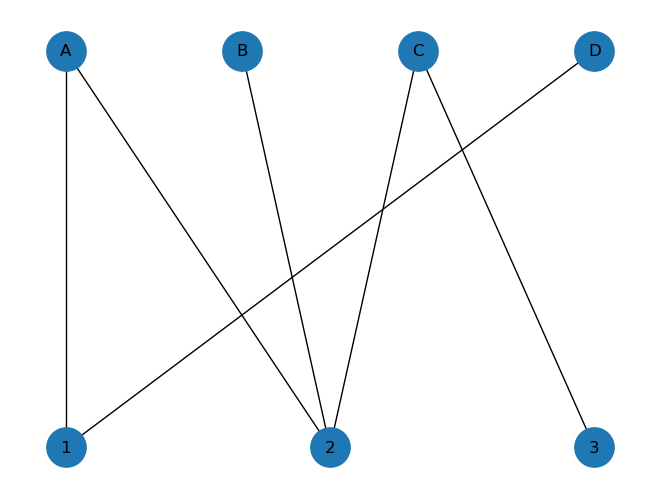

In [45]:
from networkx.algorithms import bipartite

bipartite_graph = nx.Graph()

top_nodes = ["A", "B", "C", "D"]
bottom_nodes = [1, 2, 3]


bipartite_graph.add_nodes_from(top_nodes)
bipartite_graph.add_nodes_from(bottom_nodes)


edges = [(1, "A"), (1, "D"), (2, "A"), (2, "B"), (2, "C"), (3, "C")]

bipartite_graph.add_edges_from(edges)


pos = nx.bipartite_layout(bipartite_graph, bottom_nodes) 

pos_vertical = {node: (y, x) for node, (x, y) in pos.items()}

nx.draw(bipartite_graph, pos_vertical, with_labels=True, node_size=800)

### Explanation of what I am doing.

#### I am creating a graph where;

#### The top nodes are [A, B, C, D]. These nodes belong to one part of the bipartite set, and they only connect to nodes in the bottom layer.

#### The bottom nodes are [1, 2, 3]. These nodes form the other part of the bipartite set. They do not connect to each other, only to the top-layer nodes.

#### (b) Constructing the adjacency matrix of the bipartite graph

In [49]:
bi_adjacency = nx.to_numpy_array(bipartite_graph)
bi_adjacency

array([[0., 0., 0., 0., 1., 1., 0.],
       [0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 1., 1.],
       [0., 0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 1., 0., 0., 0.],
       [1., 1., 1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0.]])

### Explanation for the block form of the adjacency matrix.

##### The adjacency is in that form because there are no connections(edges) between
##### the top nodes and the bottom nodes, and that results in the two diagonal blocks being zero.

##### The edges between the top and bottom nodes are recorded on the off-diagonal blocks.
##### We are having the button off-diagonal block to be the transpose of the top off-diagonal block
##### because the adjacency matrix is symmetric.

#### (c) Computing the adjacency matrices of the two projected graphs

#### Creating the first and second projections and their adjacency matrix.

In [54]:
top_projection = bipartite.projected_graph(bipartite_graph, top_nodes)
bottom_projection = bipartite.projected_graph(bipartite_graph, bottom_nodes)
Adj_mat_top_proj = nx.to_numpy_array(top_projection, nodelist=top_nodes, dtype=int)
Adj_mat_down_proj = nx.to_numpy_array(bottom_projection, nodelist=bottom_nodes, dtype=int)
print(Adj_mat_top_proj)
print(Adj_mat_down_proj)

[[0 1 1 1]
 [1 0 1 0]
 [1 1 0 0]
 [1 0 0 0]]
[[0 1 0]
 [1 0 1]
 [0 1 0]]


### Explanation of the edges created in the projections.

##### Projection edges show the relationship between the top nodes and also the bottom nodes.

##### Top-layer projection edges show the relationship between top nodes through common bottom nodes.

##### Bottom-layer projection edges show the relationship of the bottom nodes through common top nodes.

### (d) Computing the average degree of the top nodes and bottom nodes

In [57]:
avg_top_degree = sum(dict(bipartite_graph.degree(top_nodes)).values()) / len(top_nodes)
avg_bottom_deg = sum(dict(bipartite_graph.degree(bottom_nodes)).values()) / len(bottom_nodes)
print(f"Average degree of the top node is {avg_top_degree}")
print(f"Average degree of the bottom node is {avg_bottom_deg}")


Average degree of the top node is 1.5
Average degree of the bottom node is 2.0


### (e) Computing the average degree in each projected network

In [59]:
top_proj_degree = sum(dict(top_projection.degree()).values()) / len(top_projection)
bottom_proj_deg = sum(dict(bottom_projection.degree()).values()) / len(bottom_projection)
print(f"The average degree of top projection is {top_proj_degree}")
print(f"The average degree of bottom projection is {bottom_proj_deg}")

The average degree of top projection is 2.0
The average degree of bottom projection is 1.3333333333333333


### Explanation

The average degrees in the projected graphs differ from the original bipartite degrees because projection creates edges between nodes that share a common neighbor, adding new same-layer connections. This makes the projected networks either denser or sparser than the original bipartite graph, which explains why the average degrees change.

### Question 3

### (a) 

In [64]:
G = nx.read_edgelist("facebook_combined.txt")

### (a. i) Computing the number of nodes and edges

In [66]:
num_nodes = nx.number_of_nodes(G)
num_edges = nx.number_of_edges(G)
print(f"The number of nodes is {num_nodes}")
print(f"The number of edges is {num_edges}")

The number of nodes is 4039
The number of edges is 88234


### (a. ii) Computing the maximum and minimum degrees

In [68]:
deg_of_G = dict(nx.degree(G))
max_deg = max(deg_of_G.values())
min_deg = min(deg_of_G.values())
print(f"Maximum and minimum degrees are {max_deg} and {min_deg} respectively")

Maximum and minimum degrees are 1045 and 1 respectively


### (a. iii) Finding the average of degrees

In [70]:
list_degrees = deg_of_G.values()
avg_deg = sum(list_degrees)/ len(list_degrees)
print(f"The average degree is {avg_deg}")

The average degree is 43.69101262688784


### (a. iv) Computing the numbers of triangles

In [72]:
Adj = nx.to_numpy_array(G)
adj3 = Adj @ Adj @ Adj
no_of_tri = (1/6) * sum(np.diag(adj3))
print(f"The number of triangles is {no_of_tri}")

The number of triangles is 1612010.0


### (a. v) Computing the average clustering coefficient

In [74]:
avg_clus_coeff = nx.average_clustering(G)
print(f"The average clustering coefficient is {avg_clus_coeff}")

The average clustering coefficient is 0.6055467186200862


### (a. vi) Showing that the graph is sparse.

In [76]:
max_edges = (num_nodes*(num_nodes-1))/2


sparsity_ratio = num_edges / max_edges


if sparsity_ratio < 0.1:
    print("The graph is sparse")
else:
    print("The graph is dense")

The graph is sparse


### (a. vii) Visualizing the subgraph

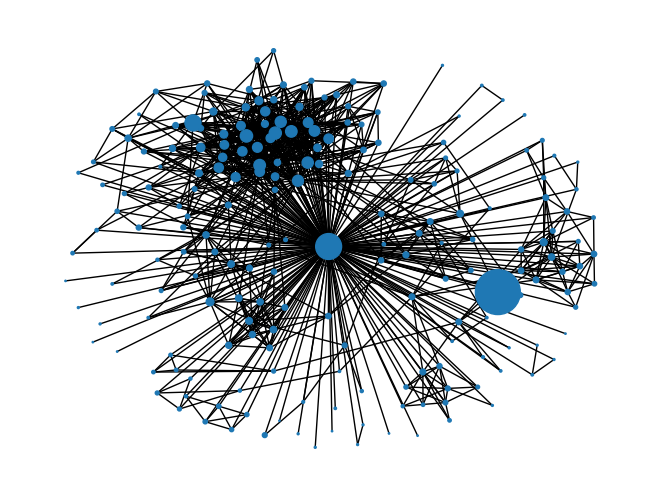

In [78]:
nodes_200 = list(G.nodes())[:200]
sub_graph = G.subgraph(nodes_200)


sizes = [deg_of_G[n] for n in sub_graph.nodes()]

nx.draw(sub_graph, node_size=sizes)
plt.show()

### (b) Computing edge density

#### My own algorithm compared with nx.density(G)

In [81]:
def edge_density(G):
    return (2*num_edges) / (num_nodes*(num_nodes-1))

print(f" edge_density: {edge_density(G)}:, nx.density: {nx.density(G)}" )

 edge_density: 0.010819963503439287:, nx.density: 0.010819963503439287


### (c. i) Plotting the degree centrality 

Text(0, 0.5, 'Frequency')

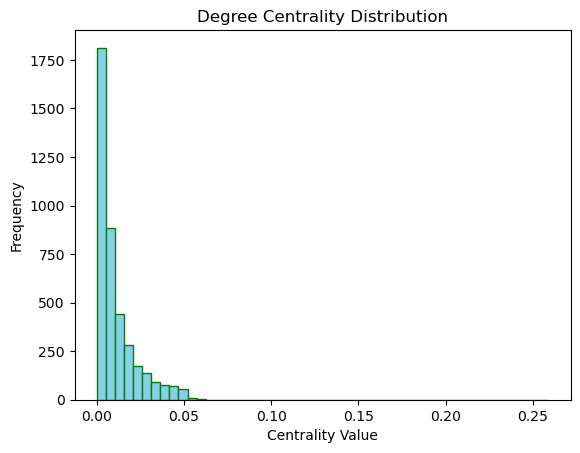

In [83]:
deg_cent = nx.degree_centrality(G)
cen_values = list(deg_cent.values())

plt.hist(cen_values, bins=50, color='skyblue', edgecolor='green')
plt.title('Degree Centrality Distribution')
plt.xlabel('Centrality Value')
plt.ylabel('Frequency')


### Comment

Most of the nodes have very low degree centrality.

The graph clusters near 0, indicating that many nodes have very few connections.

### (c. ii) Plotting the betweenness centrality

In [ ]:
Betw_cen=nx.betweenness_centrality(G)
Btw_values = list(Betw_cen.values())
plt.hist(Btw_values, bins=50, color='salmon', edgecolor='black')
plt.title('Betweenness Centrality Distribution')
plt.xlabel('Centrality Value')
plt.ylabel('Frequency')


### Comment 

Almost all the nodes have extremely small betweenness values and this is common in large sparse graph.

### (c. iii) Plotting the closeness centrality

In [ ]:
Clos_cen = nx.closeness_centrality(G)
Clos_values=list(Clos_cen.values())
plt.hist(Clos_values, bins=50, color='gold', edgecolor='black')
plt.title('Closeness Centrality Distribution')
plt.xlabel('Centrality Value')
plt.ylabel('Frequency')


### Comment

The distances between the nodes are very short because values fall roughly between 0.20 and 0.33. 

The vertical spike of the graph shows that many nodes share a similar average distance to others.

### (c. iv) Plotting the eigenvector centrality

In [ ]:
Eig_cen=nx.eigenvector_centrality(G)
Eigen_values=list(Eig_cen.values())
plt.hist(Eigen_values, bins=50, color='lightgreen', edgecolor='black')
plt.title('Eigenvector Centrality Distribution')
plt.xlabel('Centrality Value')
plt.ylabel('Frequency')

### Comment

Almost all the nodes in the network have eigenvector centrality values very close to 0.

#### (d) My own algorithm for clustering coefficient compared with nx.clustering(G)

In [ ]:
def clustering_coeff_node(G, v):
    neigh = set(G.neighbors(v))
    k = len(neigh)
    if k < 2:
        return 0.0
    links = 0
    for u in neigh:
        for w in neigh:
            if u < w and G.has_edge(u,w):
                links += 1
   
    return (2*links) / (k*(k-1))


v = list(G.nodes())[0]
print(f"clustering coefficient of a node: {clustering_coeff_node(G, v)},  nx.clustering; {nx.clustering(G, v)}")

## (e) 

In [ ]:
deg_values = list(deg_of_G.values())
unique, counts = np.unique(deg_values, return_counts=True)
P_k = counts / sum(counts)  # degree distribution
CCDF = 1 - np.cumsum(P_k)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.loglog(unique, P_k, marker='')
plt.xlabel("Degree k"); plt.ylabel("P(k)")
plt.title("Degree Distribution (log-log)")

plt.subplot(1,2,2)
plt.loglog(unique, CCDF, marker='')
plt.xlabel("Degree k"); plt.ylabel("1 - CDF(k)")
plt.title("Complementary CDF")

plt.tight_layout()
plt.show()

### (f) Computing the average shortest path length

In [ ]:
Average_shortest_length = nx.average_shortest_path_length(G)
print(f"The average shortest path length is {Average_shortest_length}")

### Scatter plot

In [ ]:
Ci = nx.clustering(G)
ki = dict(G.degree())

num_nodes = list(G.nodes())   # <-- FIX

x = [ki[v] for v in num_nodes]
y = [Ci[v] for v in num_nodes]

plt.scatter(x, y, alpha=0.4)
plt.xscale('log')
plt.yscale('linear')
plt.xlabel('degree k_i')
plt.ylabel('clustering C_i')
plt.show()

### Comment

Nodes with low degree display a wide range of clustering values, while nodes with high degree generally have low clustering.

### Question 4 

#### (a) Drawing the graph by hand.

<img src="Q4.jpg" width="600" height="200" alt="Description">

#### (b) Computing degrees of each node by hand



|  |   |  |  |   |  |   |   |   | |  |
|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|
| node(i)| 1| 2| 3| 4| 5| 6| 7| 8| 9| 10|
| degree(i)| 3| 3| 3| 3| 4| 3| 2| 4|3| 2|

#### (c) Computing the degree distribution

$$
P(2)=\frac{2}{10}, \qquad P(3)=\frac{6}{10}, \qquad P(4)=\frac{2}{10}.
$$




|      |       |       |        |
|-----------|-----------|-----------|-----------|
| degree(i) | 2         | 3         | 4         |
| P(i)      | $\frac{2}{10}$ | $\frac{6}{10}$ | $\frac{2}{10}$ |

### (d)

### Cumulative Distribution

$$ 
K = 2, \qquad P(K \le 2)=\frac{1}{5}.
$$


$$
K = 3:
P(3)=\frac{3}{5}.$$

$$
P(K \le 3) = P(K = 2) + P(K = 3)
           = \frac{1}{5} + \frac{3}{5}
           = \frac{4}{5}.
$$

$$
K = 4:
P(4)=\frac{1}{5}.
$$

$$
P(K \le 4) = P(K = 2) + P(K = 3) + P(K = 4)
           = \frac{1}{5} + \frac{3}{5} + \frac{1}{5}
           = 1.
$$

|      |       |       |        |
|-----------|-----------|-----------|-----------|
| k | 2         | 3         | 4         |
| F(k)      | $\frac{1}{5}$ | $\frac{4}{5}$ | $1$ |

### Complementary Distribution

$$
\overline{F}(k) = 1 - F(k)
$$

$$
k = 2:
\overline{F}(2)=1 - F(2)
= 1 - \frac{1}{5}
= \frac{4}{5}.
$$

$$k = 3:
\overline{F}(3)=1 - F(3)
= 1 - \frac{4}{5}
= \frac{1}{5}.
$$

$$k = 4:
\overline{F}(4)=1 - F(4)
= 1 - 1
= 0.
$$


|      |       |       |        |
|-----------|-----------|-----------|-----------|
| k | 2         | 3         | 4         |
| F(k)      | $\frac{4}{5}$ | $\frac{1}{5}$ | $0$ |


### (e. i) Constructing the graph

In [ ]:
G4 = nx.Graph()
nodes4 = [1,2,3,4,5,6,7,8,9,10]
edges4 = [(1,2), (1,3), (1,4), (2,3), (2,5), (3,6), (4,5), (4,7), (5,6), (5,8), (6,9), (7,8), (8,9), (8,10), (9,10)]
G4.add_nodes_from(nodes4)
G4.add_edges_from(edges4)
nx.draw(G, with_labels = True)

### (e. ii) Extracting the degree of each node

In [ ]:
degree = dict(nx.degree(G4))
degree

### (e. iii) Plotting the degree distribution

In [ ]:
Adj4 = nx.to_numpy_array(G4) 
Adj4

In [ ]:
k = []
for i in nodes4:
    k.append(G4.degree(i))
print(sorted(k))

In [ ]:
from collections import Counter

def degree_distribution(adjA):            
    dist = Counter(k)            
    degrees = sorted(dist.keys())
    return degrees, dict(dist)


degrees, distribution = degree_distribution(A)
print("Degree distribution:", distribution)

In [ ]:
plt.figure()
plt.xticks([2,3,4],["2","3","4"] )
plt.hist(k, bins = [2,3,4,5], density= False, color = "g", align = 'left', edgecolor = 'black');
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution Histogram")
plt.show()

### (e. iv) Plotting the cumulative degree distribution

In [ ]:
F_k = [2/10, 8/10, 1]
unique_degrees = [2, 3, 4]  

plt.figure()
plt.bar(unique_degrees, F_k, align='center')
plt.xlabel('Degree k')
plt.ylabel('F(k)')
plt.title('Plot of F(k)')
plt.show()


### (f) 

My manual degree calculations match exactly with the values obtained from NetworkX, confirming that the graph was interpreted correctly. The degree distribution histogram shows that most nodes have degree 3, with only a few having degree 2 or 4. The cumulative distribution curve is smoother and always non-decreasing, while the degree distribution has sharp peaks because it counts frequencies for each individual k. No discrepancies appeared between manual and Python results.